# Exploratory Data Analysis

In [30]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
csv_path = Path("data/spotify_tracks.csv")
if not csv_path.exists():
    csv_path = Path("../data/spotify_tracks.csv")

df = pd.read_csv(csv_path)

In [32]:
print(df.head(5))

   Unnamed: 0                track_id                 artists  \
0           0  5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino   
1           1  4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward   
2           2  1iJBSr7s7jYXzM8EGcbK5b  Ingrid Michaelson;ZAYN   
3           3  6lfxq3CG4xtTiEg7opyCyx            Kina Grannis   
4           4  5vjLSffimiIP26QG5WcN2K        Chord Overstreet   

                                          album_name  \
0                                             Comedy   
1                                   Ghost (Acoustic)   
2                                     To Begin Again   
3  Crazy Rich Asians (Original Motion Picture Sou...   
4                                            Hold On   

                   track_name  popularity  duration_ms  explicit  \
0                      Comedy          73       230666     False   
1            Ghost - Acoustic          55       149610     False   
2              To Begin Again          57       210826     False   


In [33]:
print(df.dtypes)

Unnamed: 0            int64
track_id                str
artists                 str
album_name              str
track_name              str
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object


In [34]:
print(f"Number of columns : {df.shape[1]}")
print(f"Number of rows : {df.shape[0]}")

Number of columns : 21
Number of rows : 114000


In [35]:
print(df.describe())

          Unnamed: 0     popularity   duration_ms   danceability  \
count  114000.000000  114000.000000  1.140000e+05  114000.000000   
mean    56999.500000      33.238535  2.280292e+05       0.566800   
std     32909.109681      22.305078  1.072977e+05       0.173542   
min         0.000000       0.000000  0.000000e+00       0.000000   
25%     28499.750000      17.000000  1.740660e+05       0.456000   
50%     56999.500000      35.000000  2.129060e+05       0.580000   
75%     85499.250000      50.000000  2.615060e+05       0.695000   
max    113999.000000     100.000000  5.237295e+06       0.985000   

              energy            key       loudness           mode  \
count  114000.000000  114000.000000  114000.000000  114000.000000   
mean        0.641383       5.309140      -8.258960       0.637553   
std         0.251529       3.559987       5.029337       0.480709   
min         0.000000       0.000000     -49.531000       0.000000   
25%         0.472000       2.000000     -1

In [36]:
df.isna().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [37]:
print(df[df['artists'].isnull()])
df = df.dropna()

       Unnamed: 0                track_id artists album_name track_name  \
65900       65900  1kR4gIb7nGxHPI3D2ifs59     NaN        NaN        NaN   

       popularity  duration_ms  explicit  danceability  energy  ...  loudness  \
65900           0            0     False         0.501   0.583  ...     -9.46   

       mode  speechiness  acousticness  instrumentalness  liveness  valence  \
65900     0       0.0605          0.69           0.00396    0.0747    0.734   

         tempo  time_signature  track_genre  
65900  138.391               4        k-pop  

[1 rows x 21 columns]


In [38]:
df.duplicated().sum()

np.int64(0)

## Popularity

In [39]:
print(f"Mean : {df['popularity'].mean():.2f}")
print(f"Median : {df['popularity'].median():.2f}")
print(f"Standard Deviation : {df['popularity'].std():.2f}")
print(f"% of 0 (popularity == 0) : {(df['popularity'] == 0).mean() * 100:.2f}%")

Mean : 33.24
Median : 35.00
Standard Deviation : 22.30
% of 0 (popularity == 0) : 14.05%


## Track Genre

In [40]:
print(f"Number of unqiue genre : {df['track_genre'].nunique()}")
print("Number of track by genre (min and max) :", 
df['track_genre'].value_counts().min(), "/", df['track_genre'].value_counts().max())

Number of unqiue genre : 114
Number of track by genre (min and max) : 999 / 1000


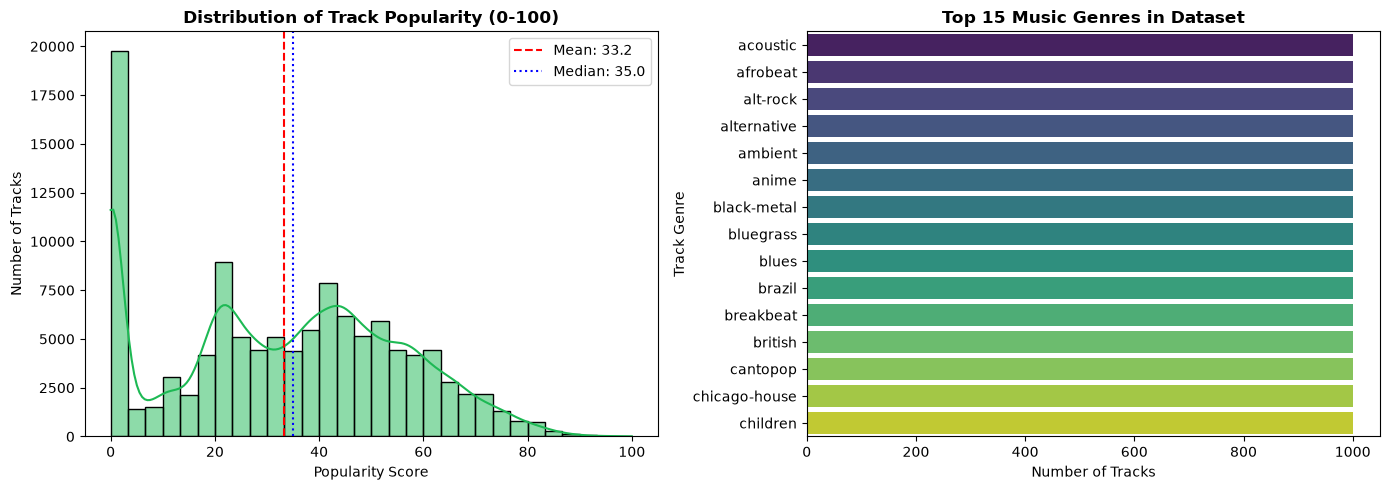

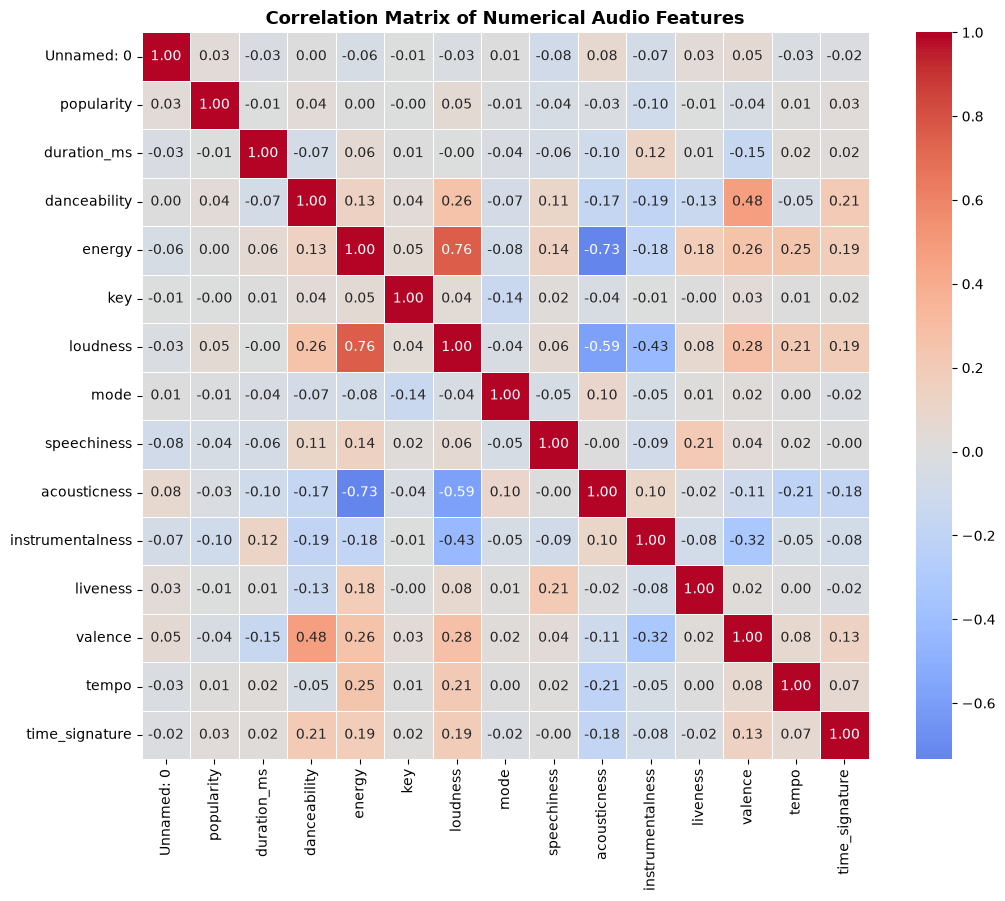

In [ ]:
fig_dir = Path("results/figures") if Path("data").exists() else Path("../results/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["popularity"], bins=30, kde=True, ax=axes[0], color="#1DB954")
axes[0].axvline(df["popularity"].mean(), color="red", linestyle="--", label=f"Mean: {df['popularity'].mean():.1f}")
axes[0].axvline(df["popularity"].median(), color="blue", linestyle=":", label=f"Median: {df['popularity'].median():.1f}")
axes[0].set_title("Distribution of Track Popularity (0-100)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Popularity Score")
axes[0].set_ylabel("Number of Tracks")
axes[0].legend()

if "track_genre" in df.columns:
    top_genres = df["track_genre"].value_counts().head(15)
    sns.barplot(x=top_genres.values, y=top_genres.index, ax=axes[1], hue=top_genres.index, palette="viridis", legend=False)
    axes[1].set_title("Top 15 Music Genres in Dataset", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Number of Tracks")
    axes[1].set_ylabel("Track Genre")

plt.tight_layout()
plt.savefig(fig_dir / "target_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(11, 9))
num_df = df.select_dtypes(include=[np.number])
corr_matrix = num_df.corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation Matrix of Numerical Audio Features", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(fig_dir / "correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()